In [ ]:
import yaml
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import statsmodels.api as sm

from scipy.stats import chi2_contingency
from scipy.stats.contingency import association

# Make plots appear in the notebook
%matplotlib inline

# Load dynamic YAML configuration to reference CSV file paths for data import
config = None  # <-- Initialize config
try:
    with open("../config.yaml", "r") as file:
        config = yaml.safe_load(file)
except:
    print("Yaml configuration file not found!")

config

df = pd.read_csv(config['input_data']['file1'])

Columns info from Amazon UK product dataset 

- uid: Unique identifier for each row. (type: int)
- asin: Product ID from Amazon. (type: str)
- title: Title of the product. (type: str)
- stars: Product rating. If 0, no ratings were found. (type: float)
- reviews: Number of customer reviews. If 0, no reviews were found. (type: int)
- price: Price of the product. (type: float, Currency: GBP)
- boughtInLastMonth: Whether the product had the Amazon BestSeller status or not. (type: bool)
- category: Indicates how many products we sold last month. (type: int)

In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [29]:
df.head(5)

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [30]:
df.nunique()

uid                  2443651
asin                 2222742
title                2077591
stars                     42
reviews                19446
price                  82916
isBestSeller               2
boughtInLastMonth         25
category                 296
dtype: int64

**Part 1: Analyzing Best-Seller Trends Across Product Categories**

In [31]:
# Create a crosstab between the product category and the isBestSeller status.
crosstab = pd.crosstab(df['category'], df['isBestSeller'], dropna=False)
crosstab

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [32]:
# Count the number of best sellers per category
best_seller_counts = df[df['isBestSeller'] == True].groupby('category')['isBestSeller'].count()
best_seller_counts.sort_values(ascending=False)

category
Grocery                   556
Health & Personal Care    552
Baby                      341
Sports & Outdoors         330
Power & Hand Tools        306
                         ... 
Computer Memory             1
Camcorders                  1
Snowboard Bindings          1
Streaming Clients           1
3D Printers                 1
Name: isBestSeller, Length: 260, dtype: int64

In [33]:
# Calculate the proportion
crosstab['best_seller_ratio'] = crosstab[True] / (crosstab[True] + crosstab[False])
crosstab = crosstab.sort_values(by='best_seller_ratio',ascending=False).head(10)
crosstab

isBestSeller,False,True,best_seller_ratio
category,,,
Grocery,9008,556,0.058135
Smart Home Security & Lighting,98,6,0.057692
Health & Personal Care,9017,552,0.057686
Mobile Phone Accessories,248,11,0.042471
Power & Hand Tools,8353,306,0.035339
"Billiard, Snooker & Pool",241,8,0.032129
Pet Supplies,9152,285,0.030200
Home Brewing & Wine Making,239,7,0.028455
Mirrors,243,7,0.028000


In [35]:
# Proportion of best-sellers per category (mean of 0/1 gives the share)
best_seller_rate = df.groupby('category')['isBestSeller'].mean().sort_values(ascending=False)

print("\nTop categories by best-seller rate:")
display(best_seller_rate.head(10))


Top categories by best-seller rate:


category
Grocery                           0.058135
Smart Home Security & Lighting    0.057692
Health & Personal Care            0.057686
Mobile Phone Accessories          0.042471
Power & Hand Tools                0.035339
Billiard, Snooker & Pool          0.032129
Pet Supplies                      0.030200
Home Brewing & Wine Making        0.028455
Mirrors                           0.028000
Wind Instruments                  0.028000
Name: isBestSeller, dtype: float64

In [ ]:
# Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'], dropna=False)

# Chi-square test for 'category' and 'isBestSeller'
chi2_statistic, chi2_p_value, dof, expected_freq = chi2_contingency(crosstab_result)

# Compute Cramér's V to understand the strength of association between best-seller status and category.
cramers_v = association(crosstab_result, method="cramer")
# n = crosstab_result.values.sum()
# r, k = crosstab_result.shape
# phi2 = chi2_statistic / n
# cramers_v = np.sqrt(phi2 / (min(k - 1, r - 1)))

print(f"Chi2 Statistic: {chi2_statistic}")
print(f"P-value: {chi2_p_value}")
print(f"Expected Frequency: {expected_freq}")

print(f"\nChi-square: {chi2_statistic:.4f}, dof: {dof}, p-value: {chi2_p_value:.6f}")
print(f"Cramér's V: {cramers_v:.4f}")

Chi2 Statistic: 36540.20270061387
P-value: 0.0
Expected Frequency: [[2.47190130e+02 8.09870149e-01]
 [4.05371878e+03 1.32812173e+01]
 [2.49183599e+02 8.16401360e-01]
 [1.69145827e+03 5.54173243e+00]
 [2.53170536e+02 8.29463782e-01]
 [8.50214439e+03 2.78556144e+01]
 [1.06650580e+02 3.49419782e-01]
 [2.57157474e+02 8.42526204e-01]
 [9.51781673e+03 3.11832664e+01]
 [1.50008526e+04 4.91473619e+01]
 [9.32544700e+03 3.05530045e+01]
 [2.38219520e+02 7.80479700e-01]
 [3.22941944e+03 1.05805616e+01]
 [9.44704859e+03 3.09514084e+01]
 [6.68808779e+03 2.19122125e+01]
 [5.26275760e+02 1.72423967e+00]
 [1.90296531e+04 6.23469391e+01]
 [2.77191835e+03 9.08164873e+00]
 [2.53170536e+02 8.29463782e-01]
 [4.04674164e+02 1.32583581e+00]
 [1.92489346e+04 6.30653723e+01]
 [3.10482764e+03 1.01723609e+01]
 [2.04330551e+02 6.69449115e-01]
 [6.28839730e+03 2.06027047e+01]
 [5.23385231e+03 1.71476942e+01]
 [9.52180367e+03 3.11963288e+01]
 [2.48186864e+02 8.13135755e-01]
 [9.46598655e+03 3.10134549e+01]
 [9.26065

In [ ]:
pd.DataFrame(expected_freq, columns=df['isBestSeller'].unique(), index=crosstab_result.index).sort_values(by='category', ascending=False)

,False,True
category,,
eBook Readers & Accessories,245.196661,0.803339
Women's Sports & Outdoor Shoes,1952.602679,6.397321
Women,17713.963660,58.036340
Window Treatments,238.219520,0.780480
Wind Instruments,249.183599,0.816401
...,...,...
Adapters,253.170536,0.829464
Action Cameras,1691.458268,5.541732
Abrasive & Finishing Products,249.183599,0.816401


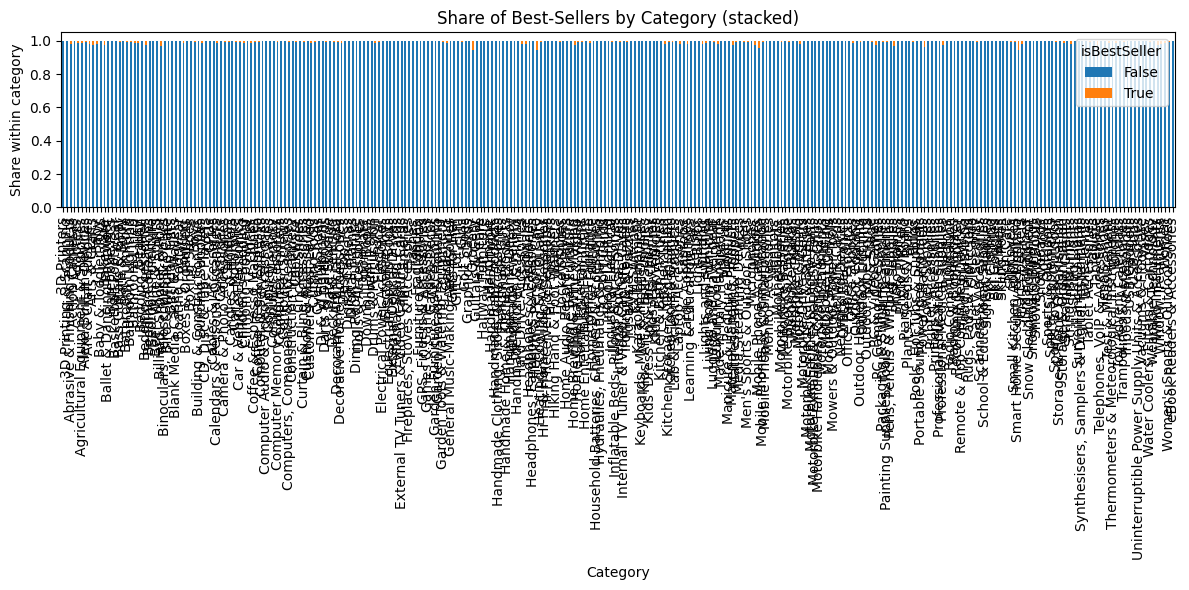

In [42]:
# Normalize counts by row to get shares within each category
ct_norm = crosstab_result.div(crosstab_result.sum(axis=1), axis=0)

# Stacked bar chart
ax = ct_norm.plot(kind='bar', stacked=True, figsize=(12, 6))
ax.set_xlabel('Category')
ax.set_ylabel('Share within category')
ax.set_title('Share of Best-Sellers by Category (stacked)')
plt.xticks(rotation=90)
plt.legend(title='isBestSeller', loc='upper right')
plt.tight_layout()
plt.show()

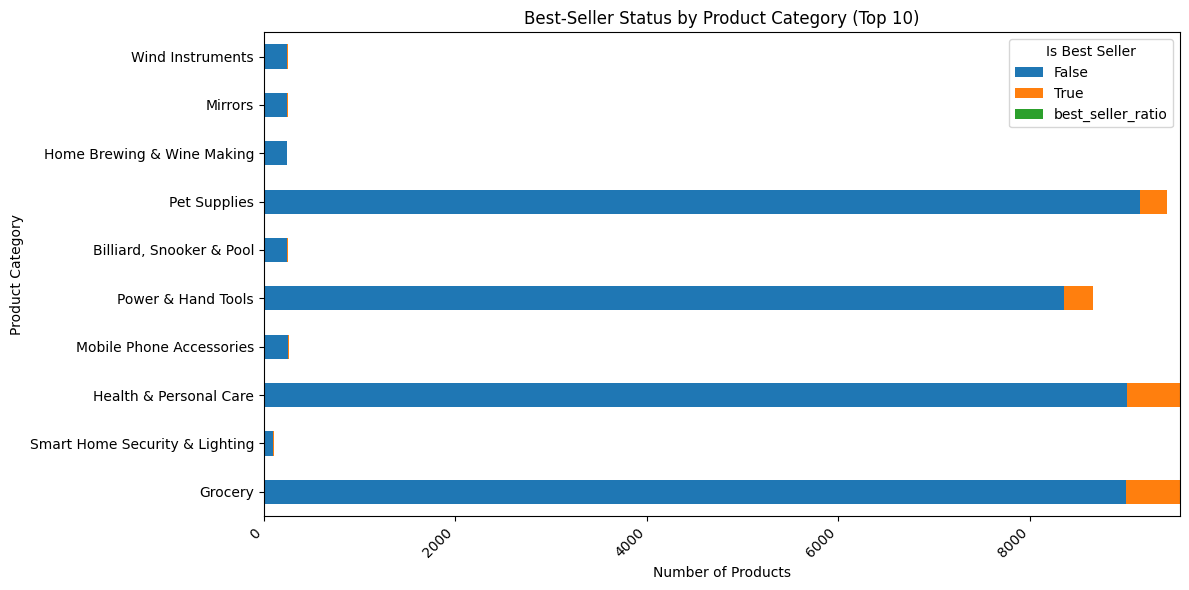

In [ ]:
# Visualize the relationship between product categories and the best-seller status using a stacked bar chart.
crosstab.plot(kind='barh', stacked=True, figsize=(12, 6))
plt.ylabel('Product Category')
plt.xlabel('Number of Products')
plt.title('Best-Seller Status by Product Category (Top 10)')
plt.legend(title='Is Best Seller')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

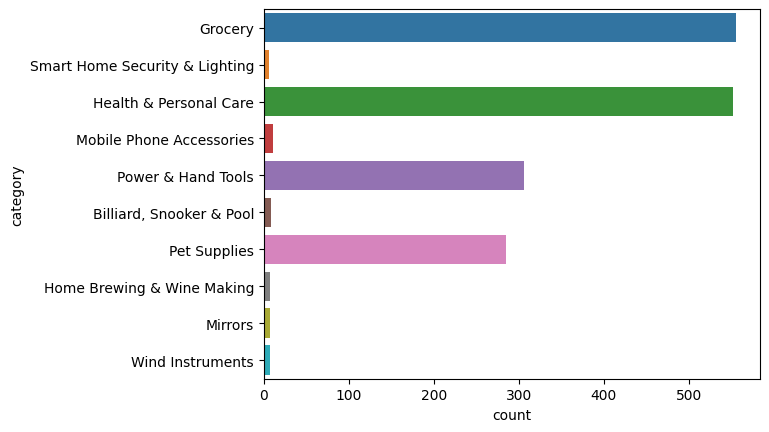

In [ ]:
sns.countplot(data=crosstab, y='category', hue='category');

**Part 2: Exploring Product Prices and Ratings Across Categories and Brands**
**2.0 Remove Outliers in `price` (IQR Rule)**
- We compute Q1 (25th percentile) and Q3 (75th percentile), the IQR = Q3 − Q1, and define **lower** and **upper** bounds:
- lower = Q1 − 1.5 × IQR  
- upper = Q3 + 1.5 × IQR  
- We filter rows where `price` is within `[lower, upper]`.

In [43]:
# Drop rows with missing price first to compute quantiles safely
price_series = df['price'].dropna()

Q1 = price_series.quantile(0.25)
Q3 = price_series.quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Keep only rows with price inside the IQR bounds
df_no_out = df[(df['price'] >= lower) & (df['price'] <= upper)].copy()

print(f"Original rows: {len(df)} | After outlier removal: {len(df_no_out)}")
print(f"IQR bounds — lower: {lower:.2f}, upper: {upper:.2f}")

Original rows: 2443651 | After outlier removal: 2115963
IQR bounds — lower: -44.01, upper: 99.99


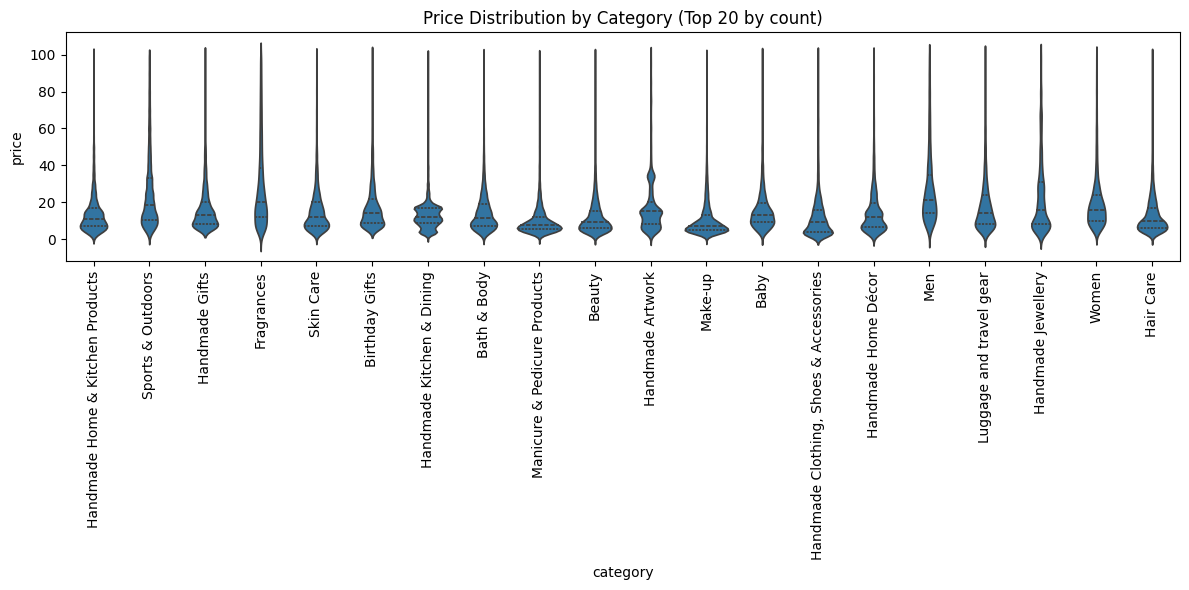

Top categories by median price (overall):


category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64

In [44]:
# Select the top 20 most frequent categories
top20_categories = df_no_out['category'].value_counts().head(20).index

# Subset to those categories only for plotting
plot_data = df_no_out[df_no_out['category'].isin(top20_categories)]

# Violin plot of price by category
plt.figure(figsize=(12, 6))
sns.violinplot(data=plot_data, x='category', y='price', inner='quartile')
plt.xticks(rotation=90)
plt.title('Price Distribution by Category (Top 20 by count)')
plt.tight_layout()
plt.show()

# Compute median price by category (without filtering by top categories)
median_price_by_cat = df_no_out.groupby('category')['price'].median().sort_values(ascending=False)
print("Top categories by median price (overall):")
display(median_price_by_cat.head(10))

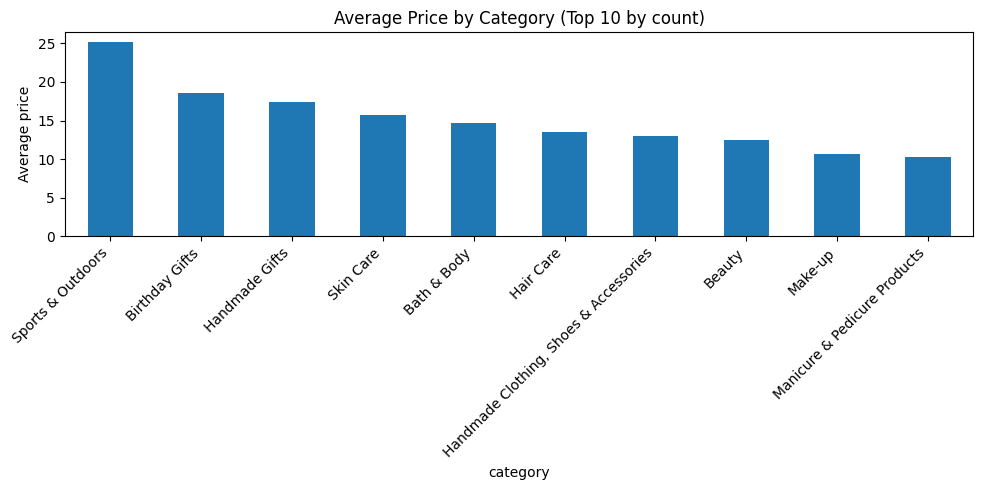

Top categories by average price (overall):


category
Motherboards         68.772432
Boxing Shoes         67.417803
Desktop PCs          66.915562
Tablets              66.552971
Graphics Cards       65.103509
Digital Frames       60.745129
Streaming Clients    60.241803
Hockey Shoes         60.094796
Computer Cases       58.339884
Skiing Poles         57.867770
Name: price, dtype: float64

In [45]:
# Top 10 categories by count
top10_categories = df_no_out['category'].value_counts().head(10).index

# Average price for those top 10
avg_price_top10 = (df_no_out[df_no_out['category'].isin(top10_categories)]
                   .groupby('category')['price']
                   .mean()
                   .sort_values(ascending=False))

# Bar plot
plt.figure(figsize=(10, 5))
avg_price_top10.plot(kind='bar')
plt.ylabel('Average price')
plt.title('Average Price by Category (Top 10 by count)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Highest average price across ALL categories (no filtering)
avg_price_all = df_no_out.groupby('category')['price'].mean().sort_values(ascending=False)
print("Top categories by average price (overall):")
display(avg_price_all.head(10))

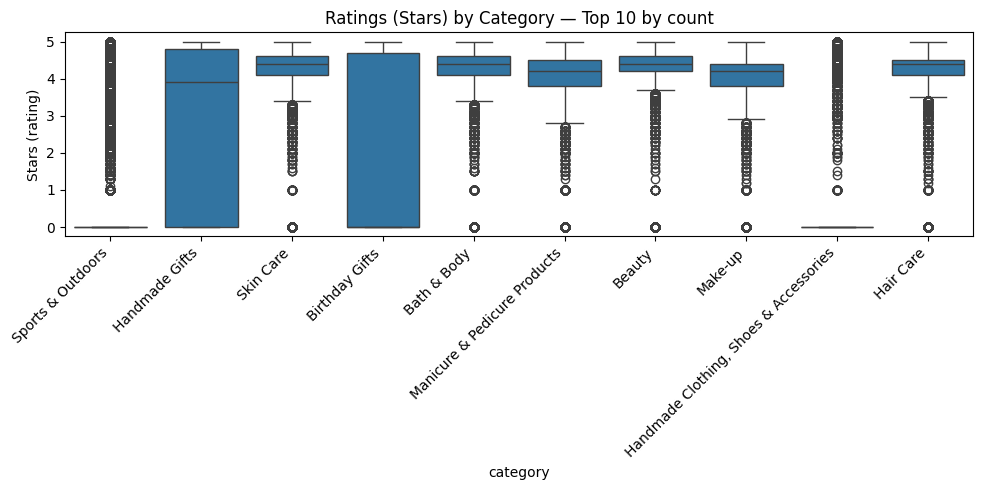

Top categories by median stars (overall):


category
Computer Memory                 4.7
Beer, Wine & Spirits            4.6
Building & Construction Toys    4.6
Office Paper Products           4.6
Kids' Play Figures              4.6
Laptop Accessories              4.6
Hobbies                         4.6
Luxury Food & Drink             4.6
Soft Toys                       4.5
Boxes & Organisers              4.5
Name: stars, dtype: float64

In [46]:
# Keep only rows with non-null stars
df_ratings = df_no_out.dropna(subset=['stars'])

top10_for_ratings = df_ratings['category'].value_counts().head(10).index

plt.figure(figsize=(10, 5))
sns.boxplot(data=df_ratings[df_ratings['category'].isin(top10_for_ratings)], x='category', y='stars')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Stars (rating)')
plt.title('Ratings (Stars) by Category — Top 10 by count')
plt.tight_layout()
plt.show()

median_stars_by_cat = df_ratings.groupby('category')['stars'].median().sort_values(ascending=False)
print("Top categories by median stars (overall):")
display(median_stars_by_cat.head(10))

**Part 3: Investigating the Interplay Between Product Prices and Ratings**

**Correlation Coefficient**
- We compute the **Pearson correlation** between `price` and `stars`.  
- A value near **0** → little/no linear relationship.  
- Positive values → as rating increases, price tends to be higher.  
- Negative values → as rating increases, price tends to be lower.

In [48]:
from scipy import stats

# Keep rows with both price and stars present
corr_df = df_no_out[['price', 'stars']].dropna()

# Pearson correlation using pandas .corr (same as class approach)
corr_value = corr_df['price'].corr(corr_df['stars'])

# (Optional) Also show scipy's pearsonr for p-value
pearson_r, pearson_p = stats.pearsonr(corr_df['price'], corr_df['stars'])

print(f"Pearson corr (pandas): {corr_value:.4f}")
print(f"Pearson r (scipy): {pearson_r:.4f}, p-value: {pearson_p:.6f}")

Pearson corr (pandas): -0.0777
Pearson r (scipy): -0.0777, p-value: 0.000000


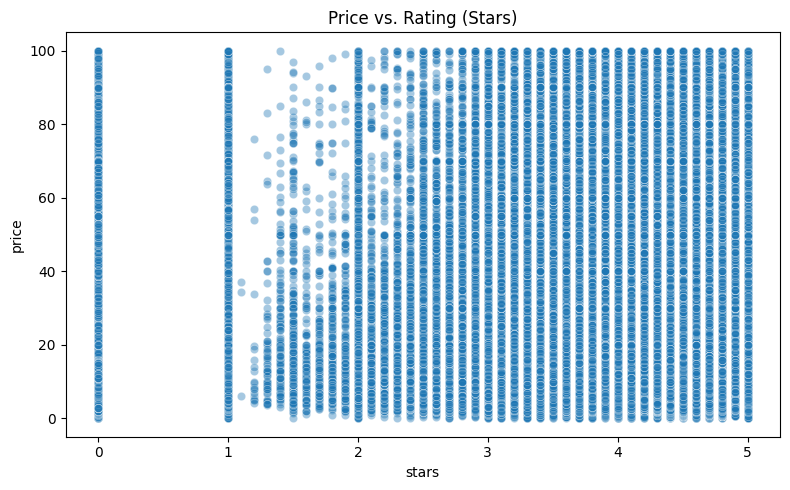

In [49]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=corr_df, x='stars', y='price', alpha=0.4)
plt.title('Price vs. Rating (Stars)')
plt.tight_layout()
plt.show()

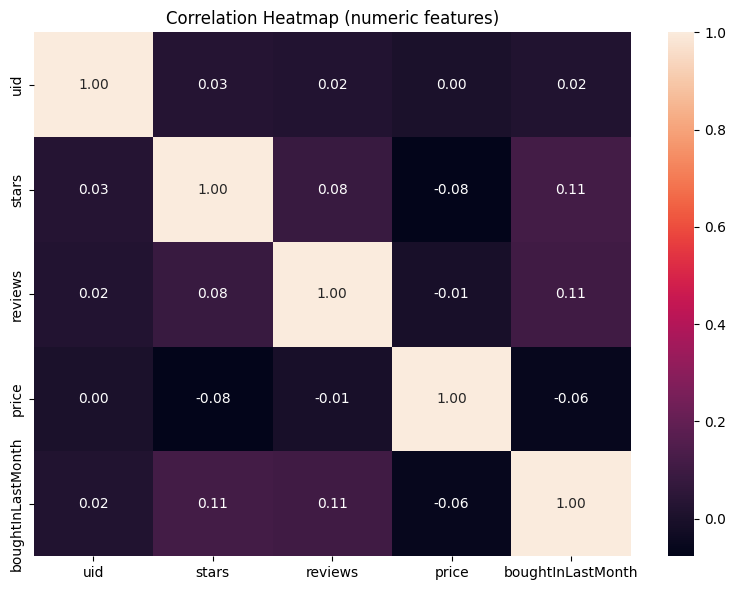

In [50]:
# Select only numeric columns to avoid errors
num_df = df_no_out.select_dtypes(include=[np.number])

# Correlation matrix
corr_mat = num_df.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_mat, annot=True, fmt='.2f', square=False)
plt.title('Correlation Heatmap (numeric features)')
plt.tight_layout()
plt.show()

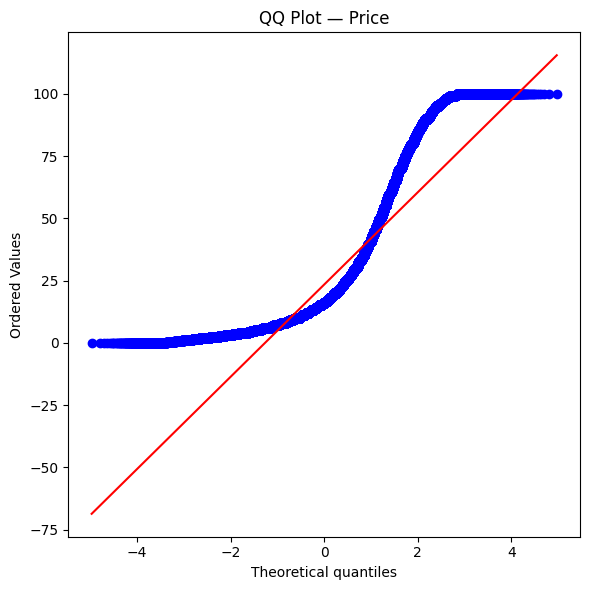

In [51]:
plt.figure(figsize=(6, 6))
stats.probplot(df_no_out['price'].dropna(), dist='norm', plot=plt)
plt.title('QQ Plot — Price')
plt.tight_layout()
plt.show()

**Bonus**: 

- Do the same analysis without taking out the outliers. What are your insights?

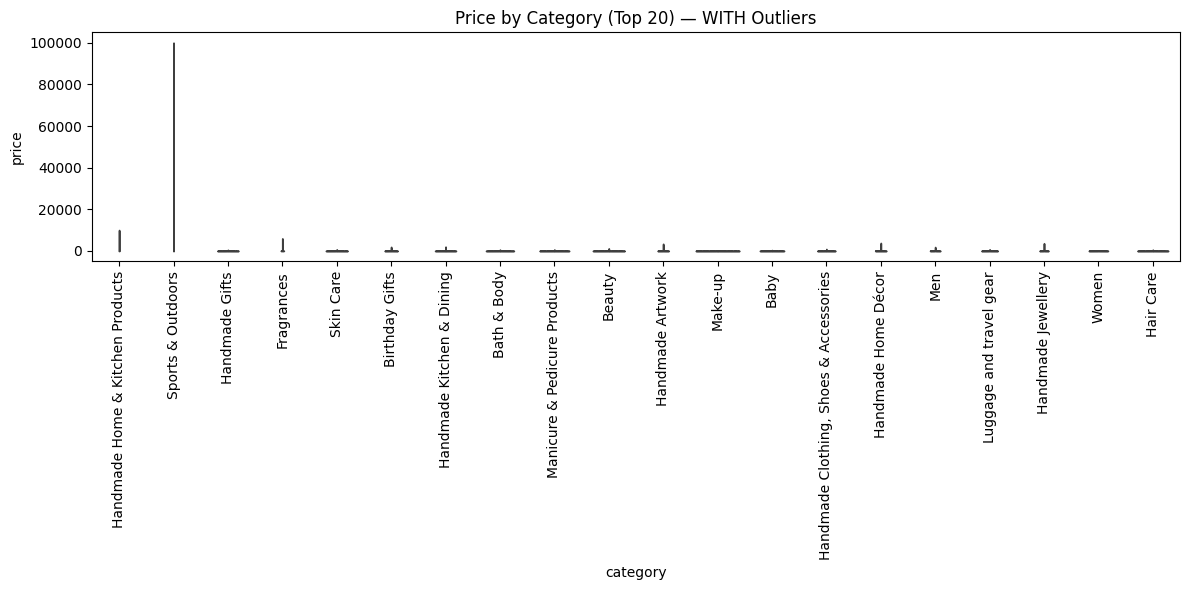

In [52]:
# Example: violin plot WITH outliers (same as 2.1 but using original df)
top20_categories_all = df['category'].value_counts().head(20).index
plot_data_all = df[df['category'].isin(top20_categories_all)]

plt.figure(figsize=(12, 6))
sns.violinplot(data=plot_data_all, x='category', y='price', inner='quartile')
plt.xticks(rotation=90)
plt.title('Price by Category (Top 20) — WITH Outliers')
plt.tight_layout()
plt.show()

**Best-seller by category:**
- Top best-seller shares by category (best_seller_ratio): Grocery (5.81%), Smart Home Security & Lighting (5.77%), Health & Personal Care (5.77%), Mobile Phone Accessories (4.25%), Power & Hand Tools (3.53%). The association between category and isBestSeller is statistically significant (χ² = 36,540.20, p < 1e-6), with Cramér’s V = 0.1223 indicating a weak effect size.

**Prices by category:**
- Using the IQR rule, prices were trimmed to [−44.01, 99.99], reducing rows from 2,443,651 → 2,115,963. Highest median prices (top 5): Desktop PCs (74.00), Boxing Shoes (69.79), Tablets (69.00), Graphics Cards (68.54), Motherboards (67.92). Highest average prices (top 5): Motherboards (68.77), Boxing Shoes (67.42), Desktop PCs (66.92), Tablets (66.55), Graphics Cards (65.10). Removing outliers stabilizes the comparisons across categories.

**Ratings by category:**
- Highest median rating (stars) categories: Computer Memory (4.7), then Beer, Wine & Spirits (4.6), Building & Construction Toys (4.6), Office Paper Products (4.6), Kids’ Play Figures (4.6).

**Price vs rating:**
- Pearson correlation = −0.0777 (p < 1e-6): a small negative linear relationship—higher prices tend to have slightly lower ratings on average. The scatter shows high variance, so price alone is not a strong predictor of rating.